In [9]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/SSL/Assignment2_SSL
!ls

KeyboardInterrupt: 

In [ ]:
!cp -r /content/drive/MyDrive/SSL/Assignment2_SSL/data /content/data

In [ ]:
!ls /content/data/train | head

In [8]:
import json
import os
import sys

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms

sys.path.insert(0, "Dino")
import Dino.utils as utils
import Dino.vision_transformer as vits
from Dino.vision_transformer import Attention, DINOHead
from Dino.fibottention import get_mask_attn_wythoff

device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

device: mps


In [2]:
EPOCHS = 50
BATCH_SIZE = 32
LR = 5e-6
GLOBAL_SIZE, LOCAL_SIZE = 160, 80
N_LOCAL = 4
OUT_DIM = 2048
TEACHER_MOMENTUM = 0.996
TEACHER_TEMP, STUDENT_TEMP = 0.04, 0.1

PATTERNS = ["random", "window", "dilated"]

In [3]:
normalize = transforms.Compose([
    transforms.ToTensor(),
])

color = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply([transforms.ColorJitter(0.4, 0.4, 0.2, 0.1)], p=0.8),
    transforms.RandomGrayscale(p=0.2),
])

class MultiCrop:
    def __init__(self):
        self.global_t = transforms.Compose([
            transforms.RandomResizedCrop(GLOBAL_SIZE, scale=(0.4, 1.0)), color,
            utils.GaussianBlur(0.5), normalize])
        self.local_t = transforms.Compose([
            transforms.RandomResizedCrop(LOCAL_SIZE, scale=(0.05, 0.4)), color,
            utils.GaussianBlur(0.5), normalize])

    def __call__(self, img):
        img = img.convert("RGB")  # some images are grayscale
        return [self.global_t(img), self.global_t(img)] + [self.local_t(img) for _ in range(N_LOCAL)]

train_set = datasets.ImageFolder("data/train", transform=MultiCrop())
train_loader = torch.utils.data.DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                                           num_workers=0, drop_last=True)
print(len(train_set), "train images,", len(train_set.classes), "classes (unused for training)")

2400 train images, 16 classes (unused for training)


In [4]:
def make_mask(pattern, heads, n_patches, seed=0):
    """(heads, N+1, N+1) mask, 1 = may attend. The [CLS] row/column stay fully connected."""
    side = int(round(n_patches ** 0.5))
    r, c = torch.arange(n_patches) // side, torch.arange(n_patches) % side
    dr, dc = (r[:, None] - r[None]).abs(), (c[:, None] - c[None]).abs()   # 2D distance between patches
    if pattern == "window":      # 3x3 neighbourhood around each patch
        m = (dr <= 1) & (dc <= 1)
    elif pattern == "dilated":   # 3x3 neighbourhood with gaps of 2 (spans a 5x5 area)
        m = (dr <= 2) & (dc <= 2) & (dr % 2 == 0) & (dc % 2 == 0)
    elif pattern == "random":    # random entries, same density as Fibottention at this size
        fib = get_mask2_attn_wythoff(heads, n_patches, True, True, 0)[:, 1:, 1:]
        g = torch.Generator().manual_seed(seed)
        m = torch.rand(heads, n_patches, n_patches, generator=g) < fib.mean()
    else:
        raise ValueError(pattern)
    mask = torch.ones(heads, n_patches + 1, n_patches + 1)
    mask[:, 1:, 1:] = m.expand(heads, n_patches, n_patches).float()
    return mask


class MaskedAttention(Attention):
    """vision_transformer.Attention with a fixed sparse mask (cached per number of tokens)."""
    def __init__(self, dim, num_heads, pattern, depth_id, **kwargs):
        super().__init__(dim, num_heads=num_heads, **kwargs)
        self.pattern = pattern
        self.depth_id = depth_id   # seeds the random pattern, so every layer gets a different one
        self.masks = {}

    def forward(self, x):
        B, N, C = x.shape
        key = (N, str(x.device))
        if key not in self.masks:
            self.masks[key] = make_mask(self.pattern, self.num_heads, N - 1, seed=self.depth_id).to(x.device)
        qkv = self.qkv(x).reshape(B, N, 3, self.num_heads, C // self.num_heads).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]

        attn = (q @ k.transpose(-2, -1)) * self.scale
        attn = attn.masked_fill(self.masks[key] == 0, float("-inf"))
        attn = attn.softmax(dim=-1)
        attn = self.attn_drop(attn)

        x = (attn @ v).transpose(1, 2).reshape(B, N, C)
        x = self.proj_drop(self.proj(x))
        return x, attn


# fraction of patch-to-patch attention kept by each pattern (global crop / local crop)
for n in [(GLOBAL_SIZE // 16) ** 2, (LOCAL_SIZE // 16) ** 2]:
    fib = get_mask_attn_wythoff(3, n, True, True, 0)[:, 1:, 1:].mean().item()
    kept = {p: make_mask(p, 3, n)[:, 1:, 1:].mean().item() for p in PATTERNS}
    print(f"{n:3d} patches:  fib {fib:.3f}  " + "  ".join(f"{p} {v:.3f}" for p, v in kept.items()))

100 patches:  fib 0.102  random 0.100  window 0.078  dilated 0.068
 25 patches:  fib 0.247  random 0.249  window 0.270  dilated 0.194


In [5]:
def vit_tiny_sparse(pattern, patch_size=16, **kwargs):
    model = vits.vit_tiny(patch_size=patch_size, **kwargs)
    for i, blk in enumerate(model.blocks):
        blk.attn = MaskedAttention(model.embed_dim, blk.attn.num_heads, pattern, depth_id=i, qkv_bias=True)
    model.apply(model._init_weights)
    return model


def build(pattern):
    backbone = vit_tiny_sparse(pattern, patch_size=16, img_size=[GLOBAL_SIZE])
    return utils.MultiCropWrapper(backbone, DINOHead(backbone.embed_dim, OUT_DIM))

In [6]:
class DINOLoss(nn.Module):
    def __init__(self, out_dim, center_momentum=0.9):
        super().__init__()
        self.center_momentum = center_momentum
        self.register_buffer("center", torch.zeros(1, out_dim))

    def forward(self, student_out, teacher_out):
        s = (student_out / STUDENT_TEMP).chunk(2 + N_LOCAL)
        t = F.softmax((teacher_out - self.center) / TEACHER_TEMP, dim=-1).detach().chunk(2)
        loss, n = 0, 0
        for i, q in enumerate(t):
            for v, p in enumerate(s):
                if v == i:
                    continue  # skip same view
                loss += torch.sum(-q * F.log_softmax(p, dim=-1), dim=-1).mean()
                n += 1
        self.update_center(teacher_out)
        return loss / n

    @torch.no_grad()
    def update_center(self, teacher_out):
        batch_center = teacher_out.mean(dim=0, keepdim=True)
        self.center = self.center * self.center_momentum + batch_center * (1 - self.center_momentum)

In [7]:
def train(pattern):
    torch.manual_seed(0)   # same initial weights, crops and data order for every pattern
    student = build(pattern).to(device)
    teacher = build(pattern).to(device)
    teacher.load_state_dict(student.state_dict())  # start teacher = student
    for p in teacher.parameters():
        p.requires_grad = False
    optimizer = torch.optim.AdamW(student.parameters(), lr=LR, weight_decay=0.04)
    dino_loss = DINOLoss(OUT_DIM).to(device)

    history = []
    for epoch in range(EPOCHS):
        student.train()
        total = 0.0
        for crops, _ in train_loader:
            crops = [c.to(device) for c in crops]
            teacher_out = teacher(crops[:2])   # teacher only sees the 2 global crops
            student_out = student(crops)       # student sees all crops
            loss = dino_loss(student_out, teacher_out)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            # EMA update of the teacher
            with torch.no_grad():
                for ps, pt in zip(student.parameters(), teacher.parameters()):
                    pt.mul_(TEACHER_MOMENTUM).add_(ps.detach(), alpha=1 - TEACHER_MOMENTUM)
            total += loss.item()

        history.append(total / len(train_loader))
        print(f"[{pattern}] epoch {epoch + 1}/{EPOCHS}  loss {history[-1]:.4f}")

    torch.save(teacher.backbone.state_dict(), f"Models/{pattern}_dino_vit_tiny_teacher.pth")
    return teacher, history


results = {}
for pattern in PATTERNS:
    teacher, history = train(pattern)
    results[pattern] = {"teacher": teacher, "history": history}

/opt/anaconda3/envs/SSL/lib/python3.11/site-packages/torch/nn/utils/weight_norm.py:145: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


[random] epoch 1/50  loss 7.6224
[random] epoch 2/50  loss 7.6522
[random] epoch 3/50  loss 7.6212
[random] epoch 4/50  loss 7.5885
[random] epoch 5/50  loss 7.5436
[random] epoch 6/50  loss 7.4322
[random] epoch 7/50  loss 7.3035
[random] epoch 8/50  loss 7.2415
[random] epoch 9/50  loss 7.2406
[random] epoch 10/50  loss 7.2463
[random] epoch 11/50  loss 7.2483
[random] epoch 12/50  loss 7.2359
[random] epoch 13/50  loss 7.2349
[random] epoch 14/50  loss 7.2684
[random] epoch 15/50  loss 7.2617
[random] epoch 16/50  loss 7.2655
[random] epoch 17/50  loss 7.2606
[random] epoch 18/50  loss 7.2626
[random] epoch 19/50  loss 7.2590
[random] epoch 20/50  loss 7.2750
[random] epoch 21/50  loss 7.2678
[random] epoch 22/50  loss 7.2755
[random] epoch 23/50  loss 7.2790
[random] epoch 24/50  loss 7.2600
[random] epoch 25/50  loss 7.2505
[random] epoch 26/50  loss 7.2485
[random] epoch 27/50  loss 7.2401
[random] epoch 28/50  loss 7.2400
[random] epoch 29/50  loss 7.2341
[random] epoch 30/50  l

In [10]:
eval_t = transforms.Compose([
    transforms.Lambda(lambda im: im.convert("RGB")),
    transforms.Resize(GLOBAL_SIZE), transforms.CenterCrop(GLOBAL_SIZE), normalize])

@torch.no_grad()
def extract(backbone, folder):
    ds = datasets.ImageFolder(folder, transform=eval_t)
    feats, labels = [], []
    for x, y in torch.utils.data.DataLoader(ds, batch_size=64):
        feats.append(F.normalize(backbone(x.to(device)), dim=1).cpu())
        labels.append(y)
    return torch.cat(feats), torch.cat(labels)

ks = [1, 5, 10, 20, 50, 100]
chance = 1 / len(train_set.classes)
for pattern, r in results.items():
    backbone = r["teacher"].backbone.eval()
    train_f, train_y = extract(backbone, "data/train")
    test_f, test_y = extract(backbone, "data/test")
    sim = test_f @ train_f.T
    k_acc = [(train_y[sim.topk(kk, dim=1).indices].mode(dim=1).values == test_y).float().mean().item() for kk in ks]
    r["k_acc"] = dict(zip(map(str, ks), k_acc))
    r["accuracy"] = r["k_acc"]["20"]
    print(f"{pattern:<8} 20-NN test accuracy: {r['accuracy']:.3f}  (chance = {chance:.3f})")


random   20-NN test accuracy: 0.285  (chance = 0.062)
window   20-NN test accuracy: 0.295  (chance = 0.062)
dilated  20-NN test accuracy: 0.310  (chance = 0.062)


not found, skipping: dino_results.json
not found, skipping: fib_dino_results.json


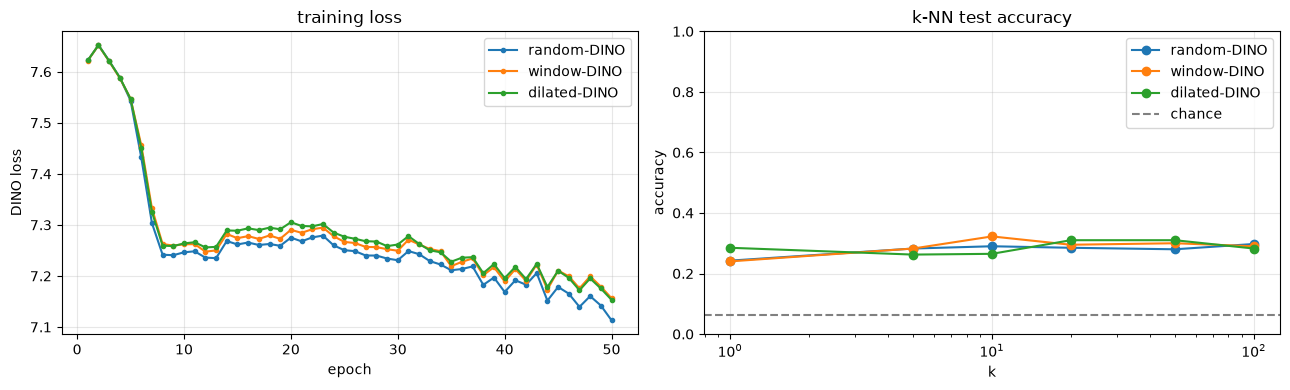

model            20-NN acc  final loss
dilated-DINO         0.310      7.1532
window-DINO          0.295      7.1564
random-DINO          0.285      7.1132


In [11]:
# Compare with dense DINO and Fib-DINO too, if their results files exist
compare = {f"{p}-DINO": r for p, r in results.items()}
for name, file in {"DINO": "dino_results.json", "Fib-DINO": "fib_dino_results.json"}.items():
    if os.path.exists(file):
        compare[name] = json.load(open(file))
    else:
        print("not found, skipping:", file)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, r in compare.items():
    axes[0].plot(range(1, len(r["history"]) + 1), r["history"], marker=".", label=name)
    axes[1].plot([int(kk) for kk in r["k_acc"]], list(r["k_acc"].values()), marker="o", label=name)
axes[0].set(title="training loss", xlabel="epoch", ylabel="DINO loss")
axes[1].axhline(chance, color="gray", ls="--", label="chance")
axes[1].set(title="k-NN test accuracy", xlabel="k", ylabel="accuracy", xscale="log", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"{'model':<16}{'20-NN acc':>10}{'final loss':>12}")
for name, r in sorted(compare.items(), key=lambda kv: -kv[1]["accuracy"]):
    print(f"{name:<16}{r['accuracy']:>10.3f}{r['history'][-1]:>12.4f}")